[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/04_footprints_zonal_radar_variables.ipynb)


# บทที่ 04 — Cloud footprint และ zonal statistics กับตัวแปรเรดาร์ (Z, Doppler, dual-pol, HID)

เส้นทางพายุบอก "ไปทางไหน" ส่วน **footprint** บอก "กวาดพื้นที่ไหน" บทนี้ดึงค่าตัวแปรเรดาร์ภายในเซลล์ทุกเวลาที่วัดจริง แล้วสรุปเป็นรายเส้นทาง เพื่อถามว่า **พายุอายุยาวมีโครงสร้างภายในต่างจากพายุอายุสั้นหรือไม่** — ลูกเห็บมากกว่า? ปั่นป่วนกว่า? ลมแยกออกแรงกว่า?

### วัตถุประสงค์การเรียนรู้
1. อธิบาย footprint ของเส้นทาง และสร้าง polygon สำหรับใช้ใน GIS
2. อธิบายตัวแปรเรดาร์ที่สรุปต่อเซลล์ (Z, KDP, ZDR, EDR, divergence, azimuthal shear, สัดส่วน HID) และเหตุที่ใช้เฉพาะภาพจริงทุก 15 นาที
3. ทำ zonal statistics ของกริดภายใน footprint
4. แบ่งเส้นทางเป็นกลุ่มอายุ สั้น/กลาง/ยาว แล้วเปรียบเทียบด้วย boxplot, Kruskal–Wallis และ Cliff's δ
5. อธิบายว่าทำไม p-value แบบปกติ "ดีเกินจริง" เมื่อเส้นทางมาจากวันเดียวกัน และใช้การสลับป้ายภายในวัน (stratified permutation) แทน

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 2 core


In [2]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats, ndimage
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M, geo as G, data as D, analysis as A, track_tools as tt
s = load_settings()
M.setup_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DEM = G.load_dem(s)                                   # (array, extent) — สร้างจาก Copernicus ครั้งแรกถ้ายังไม่มี
idx = D.day_index()
KEY_DAYS = list(idx.loc[idx["in_repo"], "day"]) if len(idx) else [pd.Timestamp("2024-05-03")]
KEY = KEY_DAYS[0]                                     # วันหลักที่มีกริดใน repo (เปลี่ยนเป็นวันอื่นได้ จะดาวน์โหลดจาก Zenodo)
print("วันหลักใน repo:", [f"{d:%d %b}" for d in KEY_DAYS], "| ใช้วัน:", f"{KEY:%d %b %Y}")

import geopandas as gpd
TAG = "15min"          # ตัวแปรเรดาร์มาจากภาพจริง → ใช้ชุด 15 นาทีเป็นหลัก (ลองเปลี่ยนเป็น "05min_linZ")
T = A.life_classes(A.month_tracks(TAG, min_life=s["tracking"]["min_life_min"]))
C = A.month_cells(TAG)
FP = D.table(f"footprints_{TAG}.gpkg")
print(f"เส้นทาง ≥ {s['tracking']['min_life_min']} นาที: {len(T)} เส้น จาก {T['day'].nunique()} วัน | เซลล์ {len(C)} แถว")
T["life_class"].value_counts().sort_index()

วันหลักใน repo: ['03 May', '05 May', '06 May', '22 May'] | ใช้วัน: 03 May 2024
เส้นทาง ≥ 30 นาที: 2325 เส้น จาก 30 วัน | เซลล์ 14038 แถว


,count
life_class,
สั้น,1055
กลาง,904
ยาว,366


## 1. ตัวแปรที่สรุปต่อเซลล์และต่อเส้นทาง (จาก `track_tools.cell_table` ของ repo3)

| ตัวแปร | ความหมาย | สรุปต่อเซลล์ | สรุปต่อเส้นทาง |
|---|---|---|---|
| `Zmax_obs` | reflectivity สูงสุด (dBZ) | max | max ของภาพจริง |
| `hail_col_km2` | พื้นที่ที่คอลัมน์มี MH/IH-HDG และ Z ≥ 40 dBZ | ผลรวม pixel | max |
| `graupel_up_frac` | สัดส่วน graupel (RP) ในมุมยก 2–3 | สัดส่วน | max |
| `KDP95` | KDP สูงสุดในคอลัมน์ เปอร์เซ็นไทล์ 95 (°/km) | p95 | max |
| `ZDR90` | ZDR มุมต่ำสุด เปอร์เซ็นไทล์ 90 (dB) | p90 | max |
| `EDR95` | EDR$^{1/3}$ สูงสุดในคอลัมน์ p95 (m$^{2/3}$ s$^{-1}$) | p95 | max |
| `DIVmax` | divergence ตามแนวรัศมีสูงสุด (10$^{-3}$ s$^{-1}$) | max | max |
| `AZSmax` | \|azimuthal shear\| สูงสุด (10$^{-3}$ s$^{-1}$) | max | max |

$$\text{DIV} = \frac{\partial V_r}{\partial r}, \qquad \text{AzShear} = \frac{1}{r}\frac{\partial V_r}{\partial \phi}$$

divergence บวกมากใกล้พื้นบ่งชี้ลมแยกออกจาก downburst ส่วน azimuthal shear บ่งชี้การหมุน (mesocyclone) หรือแนวลมเฉือน

**ทำไมใช้เฉพาะภาพจริง:** ภาพ 5/10 นาทีสังเคราะห์จาก reflectivity เท่านั้น ไม่มี KDP, HID หรือ Doppler — ค่าเหล่านี้ในตารางเซลล์จึงเป็น NaN ที่เวลาสังเคราะห์

In [3]:
VARS = {"Zmax_obs": "Z สูงสุด (dBZ)", "hail_col_km2": "พื้นที่ลูกเห็บ (km²)", "graupel_up_frac": "สัดส่วน graupel ชั้นบน",
        "KDP95": "KDP p95 (° km⁻¹)", "ZDR90": "ZDR p90 (dB)", "EDR95": "EDR p95 (m²ᐟ³ s⁻¹)",
        "DIVmax": "divergence สูงสุด (10⁻³ s⁻¹)", "AZSmax": "|az. shear| สูงสุด (10⁻³ s⁻¹)"}
T[["uid", "lifetime_min", "life_class", "deq_max", "range_km"] + list(VARS)].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lifetime_min,2325.0,48.50,26.36,30.00,30.00,45.00,60.00,270.00
deq_max,2325.0,11.49,4.27,4.51,8.44,10.64,13.49,47.89
range_km,2325.0,154.54,55.33,5.63,113.46,163.80,200.45,236.63
Zmax_obs,2325.0,48.46,2.84,40.50,46.50,48.50,50.50,61.00
hail_col_km2,2325.0,32.47,36.28,0.00,10.00,21.00,42.00,306.00
graupel_up_frac,2227.0,0.21,0.17,0.00,0.04,0.21,0.34,0.70
KDP95,2325.0,1.49,0.91,0.02,0.84,1.32,2.02,7.93
ZDR90,2325.0,3.95,1.00,0.55,3.48,4.15,4.62,7.68
EDR95,2107.0,0.19,0.02,0.10,0.18,0.19,0.20,0.36
DIVmax,2304.0,1.51,1.43,-3.28,0.73,1.14,1.72,13.18


## 2. Footprint และแผนที่ของวันหลัก

footprint = union ของ pixel ทุกเวลาของเส้นทาง → polygon (ระบบพิกัด AEQD ของเรดาร์) ความกะทัดรัด (compactness) = พื้นที่ / พื้นที่ convex hull ค่าใกล้ 1 คือรูปทรงเรียบ ค่าต่ำคือคดเคี้ยวหรือแตกแขนง

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb04_footprints_hail.png / .pdf


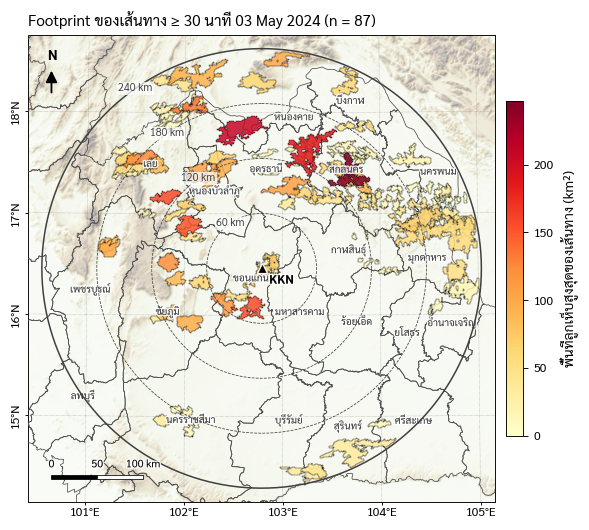

In [4]:
fk = FP[(pd.to_datetime(FP["day"]) == KEY) & FP["uid"].isin(T["uid"])].merge(T[["uid", "hail_col_km2", "life_class"]], on="uid")
fig, ax = plt.subplots(figsize=(6.6, 6.6))
M.base_map(ax, s, dem=DEM, dem_alpha=0.5)
vmax = max(float(fk["hail_col_km2"].max()), 1)
M.plot_km(fk.sort_values("hail_col_km2"), ax, column="hail_col_km2", cmap="YlOrRd", vmin=0, vmax=vmax, edgecolor="k",
          lw=0.3, alpha=0.85, zorder=10)
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(0, vmax))
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, label="พื้นที่ลูกเห็บสูงสุดของเส้นทาง (km²)")
ax.set_title(f"Footprint ของเส้นทาง ≥ 30 นาที {KEY:%d %b %Y} (n = {len(fk)})", loc="left")
M.savefig(fig, "nb04_footprints_hail")
plt.show()

## 3. Zonal statistics: ค่าของกริดภายใน footprint

ตัวอย่าง: กริด `hail_col_count` ทั้งเดือน (จำนวน volume ที่คอลัมน์มีลูกเห็บ) — footprint ไหนผ่านพื้นที่ที่เกิดลูกเห็บซ้ำบ่อย

> **หมายเหตุคุณภาพข้อมูล:** P3 พบกลุ่ม pixel ทางตะวันตกเฉียงใต้ (ระยะราว 230–238 km มุมราว 255°) ที่ "ลูกเห็บ" เกิดบ่อยกว่า echo แรงในคอลัมน์มาก ซึ่งเป็นไปไม่ได้ทางกายภาพ จึงเป็น clutter/สัญญาณรบกวน — `hail_col_count` ในบริเวณนั้นเป็น NaN (ค่าเดิมอยู่ใน `hail_col_count_raw`, หน้ากากใน `hail_artifact_mask`) และเส้นทางที่ผ่านติดป้าย `in_hail_artifact` ในตาราง


$$\overline{G}_k = \frac{1}{|F_k|}\sum_{(i,j)\in F_k} G_{ij}, \qquad F_k = \text{pixel ใน footprint ของเส้นทาง } k$$

In [5]:
with xr.open_dataset(repo_path("data", "derived", "monthly_summary_1km.nc")) as ms:
    HAILC = ms["hail_col_count"].values
_, meta = D.load_cappi(KEY)
zs = A.zonal_by_polygon(HAILC, meta, FP[FP["uid"].isin(T["uid"])], "uid", stats=("mean", "max"))
T = T.merge(zs.rename(columns={"mean": "hailfreq_mean", "max": "hailfreq_max"}), left_on="uid", right_index=True, how="left")
r, p = stats.spearmanr(T["hailfreq_mean"], T["hail_col_km2"], nan_policy="omit")
print(f"Spearman ρ (ความถี่ลูกเห็บเฉลี่ยใน footprint vs พื้นที่ลูกเห็บของเส้นทางเอง) = {r:.2f}, p = {p:.3g}")

Spearman ρ (ความถี่ลูกเห็บเฉลี่ยใน footprint vs พื้นที่ลูกเห็บของเส้นทางเอง) = 0.21, p = 2.7e-20


## 4. เปรียบเทียบกลุ่มอายุ สั้น / กลาง / ยาว

กลุ่ม: สั้น < 45 นาที, กลาง 45–<75, ยาว ≥ 75 (`A.life_classes`; อายุจาก T-DaTing เป็นจำนวนเท่าของ Δt การแบ่งด้วย tercile จึงมักได้ขอบซ้ำ)

**Kruskal–Wallis**

$$H = \frac{12}{N(N+1)}\sum_{g}\frac{R_g^2}{n_g} - 3(N+1)$$

$R_g$ = ผลรวมอันดับของกลุ่ม $g$ ภายใต้ $H_0$ ทุกกลุ่มมาจากการแจกแจงเดียวกัน

**ทำไม p-value แบบปกติไม่พอ:** เส้นทางในวันเดียวกันเกิดในบรรยากาศเดียวกัน วันที่ CAPE สูงอาจมีทั้งพายุอายุยาวและลูกเห็บมาก ความสัมพันธ์ที่เห็นจึงอาจเป็น "ผลของวัน" ไม่ใช่ "ผลของอายุ" การ **สลับป้ายกลุ่มภายในวันเดียวกัน** (stratified permutation) สร้างการแจกแจงของ $H$ ภายใต้ $H_0$ โดยคงผลของวันไว้

$$p_{\text{perm}} = \frac{1 + \#\{H^{(b)} \ge H_{\text{obs}}\}}{1 + B}$$

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb04_boxplots_life_class.png / .pdf


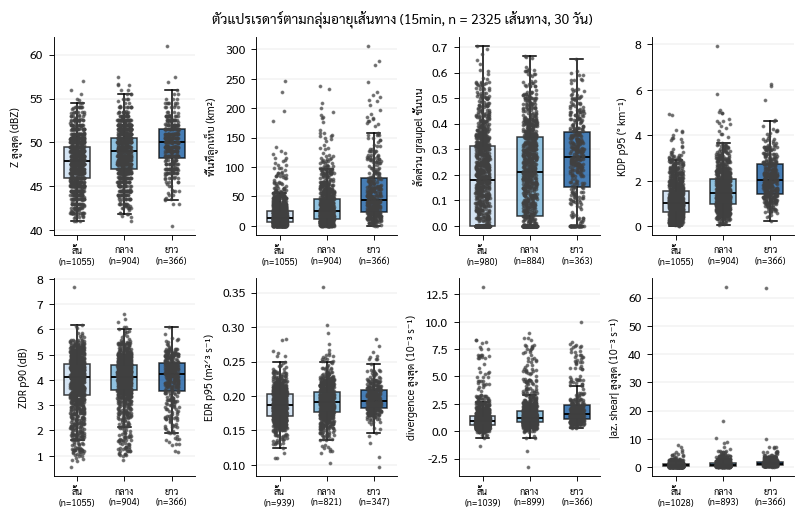

In [6]:
ORDER = ["สั้น", "กลาง", "ยาว"]
cols = ["#c6dbef", "#6baed6", "#08519c"]
fig, axs = plt.subplots(2, 4, figsize=(7.2, 4.6), layout="constrained")
for ax, (v, lab) in zip(axs.flat, VARS.items()):
    tt.boxplot_groups(ax, T, v, "life_class", order=ORDER, colors=cols, ylabel=lab, points=True)
    ax.tick_params(axis="x", labelsize=6); ax.yaxis.label.set_size(7)
fig.suptitle(f"ตัวแปรเรดาร์ตามกลุ่มอายุเส้นทาง ({TAG}, n = {len(T)} เส้นทาง, {T['day'].nunique()} วัน)", fontsize=9)
M.savefig(fig, "nb04_boxplots_life_class")
plt.show()

In [7]:
ET = A.effect_table(T, list(VARS), "life_class", order=ORDER)
ET.round(3)

,มัธยฐาน สั้น,มัธยฐาน กลาง,มัธยฐาน ยาว,H,p (classic),p (สลับในวัน),Cliff δ (ยาว vs สั้น)
ตัวแปร,,,,,,,
Zmax_obs,47.900,49.000,50.000,159.023,0.000,0.000,0.411
hail_col_km2,14.000,25.000,44.000,340.667,0.000,0.000,0.606
graupel_up_frac,0.178,0.211,0.268,52.749,0.000,0.000,0.257
KDP95,1.024,1.469,2.046,348.299,0.000,0.000,0.595
ZDR90,4.122,4.132,4.228,2.254,0.324,0.538,0.050
EDR95,0.187,0.191,0.193,43.877,0.000,0.000,0.230
DIVmax,0.940,1.190,1.555,215.801,0.000,0.000,0.487
AZSmax,0.570,0.750,1.170,199.036,0.000,0.000,0.478


**อ่านตาราง:** ดูทั้ง p-value และ Cliff's δ ค่า p เล็กแต่ δ เล็กแปลว่าต่างจริงแต่ไม่มาก และถ้า p แบบสลับภายในวันใหญ่กว่า p แบบปกติชัดเจน แปลว่าความต่างส่วนหนึ่งมาจากความต่างระหว่างวัน เมื่อมีข้อมูลหลายวัน ให้ดู `A.day_block_summary` ประกอบ (หนึ่งค่าต่อวันต่อกลุ่ม)

## 5. ความสัมพันธ์ระหว่างตัวแปร (Spearman)

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb04_spearman_matrix.png / .pdf


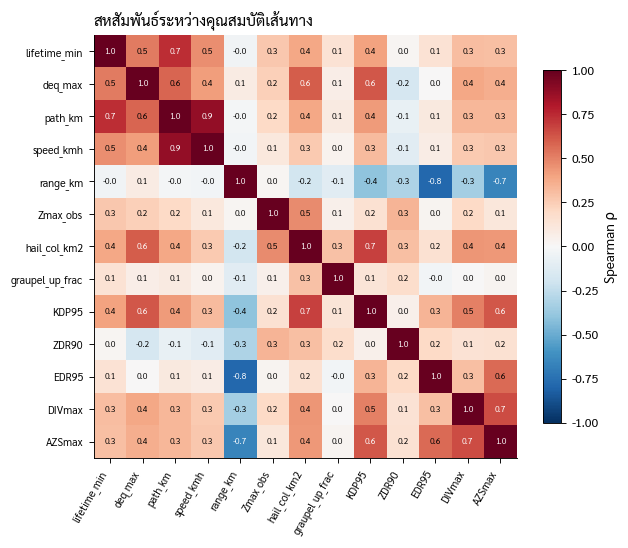

In [8]:
cols_c = ["lifetime_min", "deq_max", "path_km", "speed_kmh", "range_km"] + list(VARS)
R = T[cols_c].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_c)), cols_c, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(len(cols_c)), cols_c, fontsize=7)
for i in range(len(cols_c)):
    for j in range(len(cols_c)):
        if np.isfinite(R.iloc[i, j]):
            ax.text(j, i, f"{R.iloc[i, j]:.1f}", ha="center", va="center", fontsize=5.5, color="w" if abs(R.iloc[i, j]) > 0.6 else "k")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("สหสัมพันธ์ระหว่างคุณสมบัติเส้นทาง", loc="left")
M.savefig(fig, "nb04_spearman_matrix")
plt.show()

สังเกตแถว `range_km`: ถ้าตัวแปรเรดาร์สัมพันธ์กับระยะ (เช่น KDP หรือ EDR ลดลงตามระยะเพราะลำคลื่นกว้างขึ้น) การเปรียบเทียบกลุ่มอายุจะถูกปนด้วยตำแหน่งของพายุ บท 05 จะควบคุมตัวแปรนี้

## 6. แบบฝึกหัด

**ข้อ 1** แบ่งเส้นทางตาม **ขนาด** (tercile ของ `deq_max`: เล็ก/กลาง/ใหญ่) แล้วทำตาราง `A.effect_table` แบบเดียวกัน ขนาดหรืออายุสัมพันธ์กับลูกเห็บมากกว่ากัน

In [9]:
# เขียนโค้ดของตนเองที่นี่

In [10]:
# @title เฉลยข้อ 1
T["size_class"] = pd.qcut(T["deq_max"].rank(method="first"), 3, labels=["เล็ก", "กลาง", "ใหญ่"])
A.effect_table(T, ["hail_col_km2", "Zmax_obs", "KDP95"], "size_class", order=["เล็ก", "กลาง", "ใหญ่"]).round(3)

,มัธยฐาน เล็ก,มัธยฐาน กลาง,มัธยฐาน ใหญ่,H,p (classic),p (สลับในวัน),Cliff δ (ใหญ่ vs เล็ก)
ตัวแปร,,,,,,,
hail_col_km2,11.000,23.000,50.00,746.659,0.0,0.0,0.725
Zmax_obs,47.800,48.500,49.50,126.702,0.0,0.0,0.325
KDP95,0.822,1.339,2.01,751.092,0.0,0.0,0.753


**ข้อ 2** ใช้ตารางเซลล์ (`C`) วาดวงจรชีวิตเฉลี่ยของ `hail_col_km2` และ `Zmax` เทียบกับ "อายุสัมพัทธ์" (0 = เริ่ม, 1 = สิ้นสุด) แยกกลุ่มสั้น/ยาว ช่วงไหนของชีวิตพายุมีลูกเห็บมากที่สุด (ใช้เฉพาะเวลา `observed`)

In [11]:
# เขียนโค้ดของตนเองที่นี่

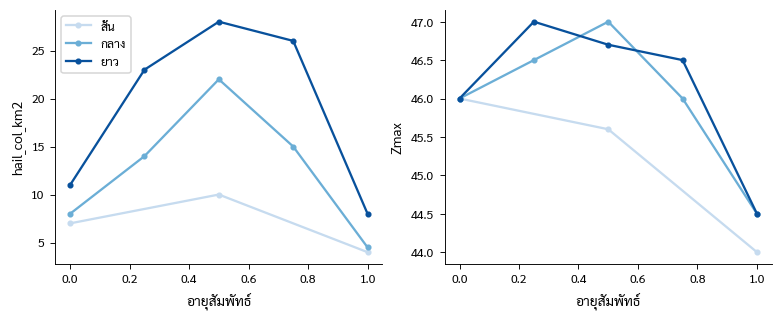

In [12]:
# @title เฉลยข้อ 2
Cc = C[C["uid"].isin(T["uid"]) & C["observed"]].merge(T[["uid", "life_class", "start", "lifetime_min"]], on="uid")
Cc["rel"] = (Cc["time"] - Cc["start"]).dt.total_seconds() / 60 / Cc["lifetime_min"].clip(lower=1)
Cc["rel_bin"] = pd.cut(Cc["rel"], np.linspace(0, 1, 6), include_lowest=True)
g = Cc.groupby(["life_class", "rel_bin"], observed=True)[["hail_col_km2", "Zmax"]].median().reset_index()
fig, axs = plt.subplots(1, 2, figsize=(7, 2.8), layout="constrained")
for ax, v in zip(axs, ["hail_col_km2", "Zmax"]):
    for cl, c in zip(ORDER, cols):
        q = g[g["life_class"] == cl]
        ax.plot(np.arange(len(q)) / max(len(q) - 1, 1), q[v], "-o", color=c, label=cl, ms=3)
    ax.set_xlabel("อายุสัมพัทธ์"); ax.set_ylabel(v)
axs[0].legend(); plt.show()

**ข้อ 3** เปลี่ยน `TAG = "05min_linZ"` ที่เซลล์แรกแล้วรันใหม่ ข้อสรุปเรื่องกลุ่มอายุเปลี่ยนหรือไม่ อธิบายด้วยผลบท 03 (เส้นทาง 5 นาทียาวกว่าและบางเส้นอาจเชื่อมผิด)

In [13]:
# เขียนโค้ดของตนเองที่นี่

In [14]:
# @title เฉลยข้อ 3
T5 = A.life_classes(A.month_tracks("05min_linZ", 30))
A.effect_table(T5, ["hail_col_km2", "Zmax_obs", "KDP95", "EDR95"], "life_class", order=ORDER).round(3)

,มัธยฐาน สั้น,มัธยฐาน กลาง,มัธยฐาน ยาว,H,p (classic),p (สลับในวัน),Cliff δ (ยาว vs สั้น)
ตัวแปร,,,,,,,
hail_col_km2,14.000,23.000,47.000,513.372,0.0,0.0,0.676
Zmax_obs,48.000,49.000,50.400,253.089,0.0,0.0,0.487
KDP95,0.899,1.264,1.900,424.285,0.0,0.0,0.625
EDR95,0.184,0.189,0.191,47.074,0.0,0.0,0.217


## 7. คำถามชวนคิด
1. `hail_col_km2` ของเส้นทางคือค่าสูงสุดของทุกเวลา พายุอายุยาวจึงมี "โอกาส" ได้ค่าสูงสุดมากกว่า (มีภาพมากกว่า) จะปรับให้ยุติธรรมอย่างไร (เช่น ค่าเฉลี่ยต่อภาพ หรือค่าในช่วงพีค)
2. HID ที่มุมยกต่ำสุดอยู่สูงต่างกันตามระยะ (0.5 km ใกล้เรดาร์, 4 km ที่ 200 km) "ลูกเห็บที่มุมต่ำสุด" จึงหมายถึงคนละชั้นของเมฆ จะออกแบบตัวแปรที่เทียบกันได้ทุกระยะอย่างไร
3. ถ้าผลต่างระหว่างกลุ่มหายไปเมื่อใช้ p แบบสลับภายในวัน ข้อสรุปทางกายภาพที่ถูกต้องคืออะไร

## 8. แนวทางต่อยอด
- ใช้ mixed-effects model (วันเป็น random effect) แทน Kruskal–Wallis เช่น `statsmodels.MixedLM`
- สร้าง hail detection algorithm จาก ZDR column / KDP column แล้วเทียบกับรายงานลูกเห็บในบท 01
- วิเคราะห์ composite ตามวงจรชีวิต (ก่อตัว–เติบโต–สลาย) ของตัวแปร dual-pol

**อ้างอิง:** Besic et al. (2016) *AMT* 9, 4425–4445; Kumjian (2013) *J. Operational Meteor.* 1, 226–242; Williams & Meymaris (2016) PyTDA; Cliff (1993) *Psychol. Bull.* 114, 494–509